In [5]:
import numpy as np

import sympy as sp

from sympy import sin
import time
import math

from utils import ( 
        get_fitted_scaler_from_csv, 
        clean_point, 
        symbolic_gradient, 
        mean_absolute_error_numpy, 
        get_distances_and_features_ckdtree,
        calculate_weight_matrix,
        predict_gibbs_energy_arrays,
        get_neighbors,
        COLUMN_TO_VAR
)

# Example usage
file_path = "/home/couchbucks/Documents/saketh/regression/regression/718_all/718_all.csv"
target_col = 'Gibbs_energy'
scaler, scaled_df = get_fitted_scaler_from_csv(file_path, target_col, scale_data=False)


# Calculate the number of rows to sample (80% of the DataFrame)
sample_size = int(len(scaled_df) * 0.8)

# Randomly sample 80% of the rows
reference_df = scaled_df.sample(n=sample_size, random_state=42)

# Specify the new order of columns
new_order = [
    'Temperature_[K]',
    'Mass_fraction_Nb',
    'Mass_fraction_Al',
    'Mass_fraction_Ti',
    'Mass_fraction_Mo',
    'Mass_fraction_Fe',
    'Mass_fraction_Cr',
    # 'Mass_fraction_Ni'
]


ref_gibbs = np.array(reference_df['Gibbs_energy'])

reference_df_rename = reference_df[new_order].rename(columns=COLUMN_TO_VAR)

df_reset_ref = reference_df_rename.reset_index(drop=True)

# Convert the DataFrame to a NumPy array
ref_points = np.array([clean_point(point) for point in df_reset_ref.values])


sampled_indices = reference_df.index

# Select the remaining 20% of the rows that were not sampled
remaining_df = scaled_df.drop(sampled_indices)

test_gibbs = np.array(remaining_df['Gibbs_energy'])

# Rename columns and reorder for consistency
remaining_df = remaining_df[new_order].rename(columns=COLUMN_TO_VAR)

df_reset = remaining_df.reset_index(drop=True)

# Convert the DataFrame to a NumPy array
query_points = np.array([clean_point(point) for point in df_reset.values])

# Function to compute the symbolic gradient of an expression with respect to each variable

x0, x1, x2, x3, x4, x5, x6 = sp.symbols('x0 x1 x2 x3 x4 x5 x6')
filter_variables = [x0, x1, x2, x3, x4, x5, x6]


relevant_variables = [x0, x1, x2, x3, x4, x5, x6]

# 0.00041702 ± 0.00228150
SIMPLIFIED_EQS = {
    'nb': 1.0327**(x0 - 0.1473) * (-x0 + 0.0214 * x1**2 - 0.0892 * x1 + 0.0117),
    'al': 0.1710 * 0.4880**x2 - 0.951 * x0 - 0.0346 * x0**2 + 0.0132 * x0 * x2 - 0.0012 * x2**2 - 0.414,
    'ti': -x0 + 0.244 * (0.5498**x3 - 1.0615),
    'mo': -x0 - 0.0321 * x0**2 + 0.0321 * sin(x4) + 0.0487,
    'fe': 1.0334572**x0 * (-x0),  # Simplified with assumptions
    # 'fe': -x0 + 0.0323 * x0**2 + 0.00302 * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': -x0 - x0**2 * 0.0323 + x6 * sin(sin(0.8701099**(x0 - x6))) * 0.0323 + 0.0305
    'cr': -x0 - 0.03286*x0**2 - 0.0241007*(-0.04523*x6**2 - x6) + 0.032916
}

EVEN_MORE_SIMPLIFIED_EQS = {
    'nb': 1.03 * (-x0 + 0.0214 * x1**2 - 0.089 * x1 + 0.0117),
    'al': 0.171 * 0.5**x2 - x0 - 0.035 * x0**2 + 0.013 * x0 * x2 - 0.0012 * x2**2 - 0.414,
    'ti': -x0 + 0.244 * (0.55**x3 - 1.06),
    'mo': -x0 - 0.032 * x0**2 + 0.032 * sin(x4) + 0.05,
    'fe': 1.03* (-x0),  # Simplified with assumptions
    # 'fe': -x0 + 0.0323 * x0**2 + 0.00302 * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': -x0 - x0**2 * 0.0323 + x6 * sin(sin(0.8701099**(x0 - x6))) * 0.0323 + 0.0305
    'cr': -x0 - 0.033*x0**2 - 0.024*(-0.045*x6**2 - x6) + 0.033
}

EVEN_EVEN_MORE_SIMPLIFIED_EQS = {
    'nb': -x0 + 0.021 * x1**2 - 0.089 * x1 + 0.012,
    'al': 0.17 * 0.5**x2 - x0 - 0.035 * x0**2 + 0.013 * x0 * x2 - 0.001 * x2**2 - sp.sqrt(2),
    'ti': -x0 + 0.244 * (0.5**x3 - 1),
    'mo': -x0 - 0.032 * x0**2 + 0.032 * sin(x4) + 0.05,
    'fe': -x0,  # Simplified with assumptions
    # 'fe': -x0 + 0.0323 * x0**2 + 0.00302 * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': -x0 - x0**2 * 0.0323 + x6 * sin(sin(0.8701099**(x0 - x6))) * 0.0323 + 0.0305
    'cr': -x0 - 0.033*x0**2 - 0.025*(-0.045*x6**2 - x6) + 0.033
}

EVEN_EVEN_EVEN_MORE_SIMPLIFIED_EQS = {
    'nb': -x0 + 0.02 * x1**2 - 0.09 * x1 + 0.01,
    'al': 0.17 * 0.5**x2 - x0 - 0.04 * x0**2 + 0.01 * x0 * x2 - 0.001 * x2**2 - sp.sqrt(2),
    'ti': -x0 + 0.25 * (0.5**x3 - 1),
    'mo': -x0 - 0.03 * x0**2 + 0.03 * sin(x4) + 0.05,
    'fe': -x0,  # Simplified with assumptions
    # 'fe': -x0 + 0.0323 * x0**2 + 0.00302 * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': -x0 - x0**2 * 0.0323 + x6 * sin(sin(0.8701099**(x0 - x6))) * 0.0323 + 0.0305
    'cr': -x0 - 0.03*x0**2 - 0.03*(-0.05*x6**2 - x6) + 0.03
}

EVEN_EVEN_EVEN_EVEN_MORE_SIMPLIFIED_EQS = {
    'nb': -x0 + (1/50) * x1**2 - (1/10) * x1 + (1/100),
    'al':  (1/6) * 0.5**x2 - x0 - (1/25) * x0**2 + (1/100) * x0 * x2 - (1/1000) * x2**2 - sp.sqrt(2),
    'ti': -x0 + (1/4) * (0.5**x3 - 1),
    'mo': -x0 - (1/3) * x0**2 + (1/3) * sin(x4) + (1/20),
    'fe': -x0,  # Simplified with assumptions
    # 'fe': -x0 + 0.0323 * x0**2 + 0.00302 * x0 * x5 + 0.00086 * x5**2 - 0.0323 * exp(-0.1797 * x5),
    # 'cr': -x0 - x0**2 * 0.0323 + x6 * sin(sin(0.8701099**(x0 - x6))) * 0.0323 + 0.0305
    'cr': -x0 - (1/3)*x0**2 - (1/3)*(-(1/20)*x6**2 - x6) + (1/3)
}

medium_equations = {
    'nb': 1.03271**(x0 - 0.14734)*(-x0 + 0.02140*x1**2 - 0.08920*x1 + 0.01167),
    'al': 0.48800**x2*0.37150 - x0 - 0.03637*(x0 - 0.190697 * x2)**2 - 0.43599,
    'ti': (-x0 + 0.24438*(0.54978**x3 - 1.06153)),
    'mo': -x0 + (-x0**2 + sin(-1.18954**(x0 + 0.99362) + x4) + 1.51626)*0.03205,
    # 'fe': -x0 + 0.23703/(x5 + exp(2)),
    'fe': -x0 + (-(-x0 - 0.17965141*x5*0.25846276)**2 + sp.log(-0.17965141*x5))*0.0322746291149881, # sp.log = exp = e^(x)
    'cr': -x0 - 0.03286*x0**2 - 0.0241007*(-0.04523*x6**2 - x6) + 0.032916
    # Add other elements...
}


full_equations = {
    # 'nb': (-x0 - 0.079403974*x1*(0.73890084**x1 + 0.04306198) + 0.0091454005)/math.sqrt(0.9366797**(x0 - 0.10534109)),
    'nb': (-x0 - 0.079403974*x1*(0.73890084**x1 + 0.04306198) + 0.0091454005)/((0.9366797**(x0 - 0.10534109))**0.5),
    'al': 0.352343650290714*0.4862979**x2 - 0.352343650290714*1.2002983**(sp.log(x0**2)**(1/4)) - 0.950689196092642*x0, # sp.log = exp = e^(x)
    'ti': (0.22641088*0.5306325**x3 - x0 - 0.242776)*((1.0679464**(x0 - 0.3363843*x3 - 0.45122325))**0.5),
    # 'ti': 'ti': (0.22641088*0.5306325**x3 - x0 - 0.242776)*math.sqrt(1.0679464**(x0 - 0.3363843*x3 - 0.45122325)),
    'mo': 1.0331628**x0*(-x0 - 1*(-0.02004116) + 0.0105717776067225*(-x4 - 0.3921473)**2/1.0812141**(2*x0*x4)),
    'fe': 1.0334572**x0*(-x0 + 0.23702882/(x5 + sp.log(2*(1.0334572**x5)**(x0 - 1*(-0.49997815))))),
    'cr': -x0 + (-0.7220202*1.086616**(-x0 + x6)*x6 + x0**2)*(-0.033271) - 1*(-0.032068063)
}

acc_full_equations = {
    # 'nb': (-x0 - 0.079403974*x1*(0.73890084**x1 + 0.04306198) + 0.0091454005)/math.sqrt(0.9366797**(x0 - 0.10534109)),
    'nb': (-x0 - 0.079403974*x1*(0.73890084**x1 + 0.04306198) + 0.0091454005)/sp.sqrt(0.9366797**(x0 - 0.10534109)),
    'al': (0.488004**x2*0.37150496 - x0 - 0.0363654030181225*(x0 + x2*(-0.19069715))**2 - 1*0.4359865)*0.9507373, # sp.log = exp = e^(x)
    'ti': (0.22641088*0.5306325**x3 - x0 - 0.242776)*sp.sqrt(1.0679464**(x0 - 0.3363843*x3 - 0.45122325)),
    # 'ti': 'ti': (0.22641088*0.5306325**x3 - x0 - 0.242776)*math.sqrt(1.0679464**(x0 - 0.3363843*x3 - 0.45122325)),
    'mo': -x0 + (-x0**2 + sin(-1.1895381**(x0 + 0.99361753) + x4) + 1.51626345732225)*0.03205326,
    'fe': 1.0334572**x0*(-x0 + 0.23702882/(x5 + sp.log(2*(1.0334572**x5)**(x0 - 1*(-0.49997815))))),
    'cr': -x0 + (-x0**2 + x6*sin(sin(0.8701099**(x0 - x6))) - 0.056781147)*0.032317404 + 0.032317404
}

non_weird_full_eq = {
    'nb': 1.0291201**(x0 - 0.20558353)*(-x0 + (x1 - 0.25470167*(x1**2 + 0.2880812))*(-0.08940733)),
    'al': 1.03156938690521**(x0 - 0.66138196*x2 - 1.679607)*(0.39183077*0.49847025**x2 - x0 - 0.468932133457517), # sp.log = exp = e^(x)
    'ti': 0.9681053**(-x0 + 0.36640376*x3 + 0.411415692468104)*(-x0 + 0.23432513*sp.sqrt(0.29113433**x3) - 0.24907888),
    'mo': -0.032634176*x0**2 - x0 + 0.032634176*(1.19726768101373*0.86230316016784**(x0 - x4))**x4 - 0.0064035367562368, 
    'fe': -0.032786813*x0**2 - x0 + 0.032786813*sp.sqrt((0.8917202**(x0 + 1.72557701786078))**(3*x5/2)), 
    'cr': -x0 + (x0**2 - x6 - (0.950945**x0 - 1*0.22067341)**x6)*(-0.017228598)/0.5418049
}

non_normed_full_eq = {
    'nb': -17134.807*x1**0.59381795 - 2458.70910261011*sp.sqrt((0.00755910863898022*x0 + 1)**3) + 12640.3956617,
    'al': 26288.354**(0.33228657**x2) + x0*(x0*(-0.0093149645) - 66.92056) - 66.92056, 
    'ti': x0*(x0*(-0.014578786) - 761.10675 - 1*(-708.4294)) + 1.1397976 + 16079.547/((x3 + sp.log(x3))**4), # sp.log = exp = e^(x)
    'mo': 116895.229685152*x4**3 + 5956.74326993054*(-sp.sqrt(0.00355369461993378*x0 - 1) - 0.45290033711924)**3, 
    'fe': x0*(-(-0.0032811693)*x0*(x5**2)**x5 - 0.015056545*x0 - 57.19808) + 2.0679812 + 19052.342, 
    'cr': -20.030888*x0 + 7657.397*x6 - 1.3306884*sp.sqrt(x0**3) + 7657.397*sp.log(x6) + 68.968506
}

# gradients={}


# use_equations = non

# for key in use_equations:
#     gradients[key] = symbolic_gradient(use_equations[key], relevant_variables)




/home/couchbucks/Documents/saketh/regression/regression/utils.py:157: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)


ValueError: too many values to unpack (expected 2)

In [128]:
maes = {}
maes_std = {}

mapes = {}
mapes_std = {}

lower_bound = - 1
upper_bound = 500
step = 25


for epsilon in range(lower_bound, upper_bound, step):
    if epsilon == 0:
        continue

    gradients = {'nb': [-27.8784738274191*sp.sqrt((0.00755910863898022*x0 + 1)**3)/(0.00755910863898022*x0 + epsilon),
    -10174.9559663857/(x1**0.40618205 + epsilon),
    0,
    0,
    0,
    0,
    0],
    'al': [-0.018629929*x0 - 66.92056,
    0,
    -11.2124555066895*0.33228657**x2*26288.354**(0.33228657**x2),
    0,
    0,
    0,
    0],
    'ti': [-0.029157572*x0 - 52.67735,
    0,
    0,
    16079.547*(-4 - 4/(x3+1))/(x3 + sp.log(x3) + epsilon)**5,
    0,
    0,
    0],
    'mo': [-31.7526697660184*(-sp.sqrt(0.00355369461993378*x0 - 1) - 0.45290033711924)**2/sp.sqrt(0.00355369461993378*x0 - 1),
    0,
    0,
    0,
    350685.689055456*x4**2,
    0,
    0],
    'fe': [x0*(0.0032811693*(x5**2)**x5 - 0.015056545) + 0.0032811693*x0*(x5**2)**x5 - 0.015056545*x0 - 57.19808,
    0,
    0,
    0,
    0,
    0.0032811693*x0**2*(sp.log(x5**2) + 2)*(x5**2)**x5,
    0],
    'cr': [-20.030888 - 1.9960326*sp.sqrt(x0**3)/(x0 + epsilon),
    0,
    0,
    0,
    0,
    0,
    7657.397 + 7657.397/(x6 + epsilon)]}

    # Assuming `scaled_ref_data_points` is already defined
    n_ref_points = len(ref_points)
    n_features = len(relevant_variables)
    n_gradients = len(relevant_variables)  # assuming all have the same gradient dimension

    # Initialize arrays to store all gradients and gibbs energies
    all_gradients = []
    ref_gibbs = np.array(reference_df['Gibbs_energy'])


    # Populate the arrays
    for i, point in enumerate(ref_points):
        # Original point data
        original_ref_str = reference_df.iloc[i]
        
        closest_point = point
        point_dict = {relevant_variables[j]: closest_point[j] for j in range(n_features)}
        
        # Gradient expressions evaluated at the closest point
        gradient_exprs = gradients[original_ref_str.temp_class]
        gradient_at_closest = []
        
        for grad in gradient_exprs:
            if type(grad) == int:
                gradient_at_closest.append(grad)
                continue
            value = grad.evalf(subs=point_dict)
            gradient_at_closest.append(value)

        # gradient_at_closest = np.array(gradient_at_closest)
        
        # print(gradient_at_closest)oo
        # exit()
        
        # gradient_at_closest = np.array([grad.evalf(subs=point_dict) for grad in gradient_exprs], dtype=np.float64)
        
        # Store in the large arrays
        all_gradients.append(gradient_at_closest)
        # all_gibbs_energies[i] = x.gibbs_energy

    all_gradients = np.array(all_gradients)

    # Assuming 'temp_class' is the column in reference_df indicating temperature class
    # ref_points_by_class = {}
    # gibbs_by_class = {}
    # gradients_by_class = {}

    # # Loop through each unique temperature class and group the corresponding points
    # for temp_class in reference_df['temp_class'].unique():
    #     mask = reference_df['temp_class'] == temp_class
        
    #     # Filter points that belong to the current temp_class
    #     temp_class_points = reference_df[mask]
        
    #     gibbs_by_class[temp_class] = ref_gibbs[mask]
    #     # print(mask)
    #     gradients_by_class[temp_class] = all_gradients[mask]
        
    #     # Extract the points (excluding the target variable column 'Gibbs_energy')
    #     temp_class_points_values = temp_class_points.drop(columns=['Gibbs_energy', 'temp_class', 'Mass_fraction_Ni']).values # 'Mass_fraction_Ni' becomes NaN after standardization
        
    #     # Store the points grouped by class
    #     ref_points_by_class[temp_class] = temp_class_points_values
        

    NUMBER_OF_NEIGHBORS = 2

    start = time.perf_counter()

    relative_neighbors=False

    # Use `ref_points_by_class` for relative neighbors
    # distances, closest_points, gradient_array, gibbs_array = get_neighbors(
    #     query_points=query_points,
    #     ref_points_by_class=ref_points_by_class,
    #     ref_points=ref_points,  # If using absolute neighbors, pass the full set of points
    #     all_gradients=all_gradients,
    #     gradients_by_class=gradients_by_class,
    #     gibbs_by_class=gibbs_by_class,
    #     all_gibbs=ref_gibbs,
    #     n=NUMBER_OF_NEIGHBORS,
    #     relative=relative_neighbors
    # )

    distances, closest_points, gradient_array, gibbs_array = get_neighbors(
        query_points=query_points,
        ref_points_by_class=None,
        ref_points=ref_points,  # If using absolute neighbors, pass the full set of points
        all_gradients=all_gradients,
        gradients_by_class=None,
        gibbs_by_class=None,
        all_gibbs=ref_gibbs,
        n=NUMBER_OF_NEIGHBORS,
        relative=relative_neighbors
    )


    weights = calculate_weight_matrix(distances)


    predictions = predict_gibbs_energy_arrays(
        query_points, closest_points, gradient_array, gibbs_array, weights, weighted=True
    )


    y_true = test_gibbs
    y_pred = predictions
    decimals = 8


    y_true = (np.array(y_true)).astype(float)
    y_pred = (np.array(y_pred)).astype(float)

    if y_true.shape != y_pred.shape:
        raise ValueError("The lists must have the same sha2pe.")

    # Mean Absolute Error
    absolute_errors = np.abs(y_true - y_pred)
    # print(absolute_errors)

    mae = np.mean(absolute_errors)

    # print(absolute_errors)

    mae_stdev = np.std(absolute_errors)

    # Mean Absolute Percentage Error
    # Avoid division by zero
    non_zero_indices = y_true != 0



    abs_percentage_errors = np.abs((y_true[non_zero_indices] - y_pred[non_zero_indices]) / y_true[non_zero_indices])
    mape = np.mean(abs_percentage_errors)
    mape_stdev = np.std(abs_percentage_errors)
    
    maes[epsilon] = mae
    maes_std[epsilon] = mae_stdev
    
    mapes[epsilon] = mape
    mapes_std[epsilon] = mape_stdev

In [64]:
epsilon = 25

gradients = {'nb': [-27.8784738274191*sp.sqrt((0.00755910863898022*x0 + 1)**3)/(0.00755910863898022*x0 + epsilon),
-10174.9559663857/(x1**0.40618205 + epsilon),
0,
0,
0,
0,
0],
'al': [-0.018629929*x0 - 66.92056,
0,
-11.2124555066895*0.33228657**x2*26288.354**(0.33228657**x2),
0,
0,
0,
0],
'ti': [-0.029157572*x0 - 52.67735,
0,
0,
16079.547*(-4 - 4/(x3+1))/(x3 + sp.log(x3) + epsilon)**5,
0,
0,
0],
'mo': [-31.7526697660184*(-sp.sqrt(0.00355369461993378*x0 - 1) - 0.45290033711924)**2/sp.sqrt(0.00355369461993378*x0 - 1),
0,
0,
0,
350685.689055456*x4**2,
0,
0],
'fe': [x0*(0.0032811693*(x5**2)**x5 - 0.015056545) + 0.0032811693*x0*(x5**2)**x5 - 0.015056545*x0 - 57.19808,
0,
0,
0,
0,
0.0032811693*x0**2*(sp.log(x5**2) + 2)*(x5**2)**x5,
0],
'cr': [-20.030888 - 1.9960326*sp.sqrt(x0**3)/(x0 + epsilon),
0,
0,
0,
0,
0,
7657.397 + 7657.397/(x6 + epsilon)]}
# Assuming `scaled_ref_data_points` is already defined
n_ref_points = len(ref_points)
n_features = len(relevant_variables)
n_gradients = len(relevant_variables)  # assuming all have the same gradient dimension
# Initialize arrays to store all gradients and gibbs energies
all_gradients = []
ref_gibbs = np.array(reference_df['Gibbs_energy'])
# Populate the arrays
for i, point in enumerate(ref_points):
    # Original point data
    original_ref_str = reference_df.iloc[i]
    
    closest_point = point
    point_dict = {relevant_variables[j]: closest_point[j] for j in range(n_features)}
    
    # Gradient expressions evaluated at the closest point
    gradient_exprs = gradients[original_ref_str.temp_class]
    gradient_at_closest = []
    
    for grad in gradient_exprs:
        if type(grad) == int:
            gradient_at_closest.append(grad)
            continue
        value = grad.evalf(subs=point_dict)
        gradient_at_closest.append(value)
    # gradient_at_closest = np.array(gradient_at_closest)
    
    # print(gradient_at_closest)oo
    # exit()
    
    # gradient_at_closest = np.array([grad.evalf(subs=point_dict) for grad in gradient_exprs], dtype=np.float64)
    
    # Store in the large arrays
    all_gradients.append(gradient_at_closest)
    # all_gibbs_energies[i] = x.gibbs_energy
all_gradients = np.array(all_gradients)
# Assuming 'temp_class' is the column in reference_df indicating temperature class
# ref_points_by_class = {}
# gibbs_by_class = {}
# gradients_by_class = {}
# # Loop through each unique temperature class and group the corresponding points
# for temp_class in reference_df['temp_class'].unique():
#     mask = reference_df['temp_class'] == temp_class
    
#     # Filter points that belong to the current temp_class
#     temp_class_points = reference_df[mask]
    
#     gibbs_by_class[temp_class] = ref_gibbs[mask]
#     # print(mask)
#     gradients_by_class[temp_class] = all_gradients[mask]
    
#     # Extract the points (excluding the target variable column 'Gibbs_energy')
#     temp_class_points_values = temp_class_points.drop(columns=['Gibbs_energy', 'temp_class', 'Mass_fraction_Ni']).values # 'Mass_fraction_Ni' becomes NaN after standardization
    
#     # Store the points grouped by class
#     ref_points_by_class[temp_class] = temp_class_points_values
    


In [105]:
NUMBER_OF_NEIGHBORS = 2
start = time.perf_counter()
relative_neighbors=False
# Use `ref_points_by_class` for relative neighbors
# distances, closest_points, gradient_array, gibbs_array = get_neighbors(
#     query_points=query_points,
#     ref_points_by_class=ref_points_by_class,
#     ref_points=ref_points,  # If using absolute neighbors, pass the full set of points
#     all_gradients=all_gradients,
#     gradients_by_class=gradients_by_class,
#     gibbs_by_class=gibbs_by_class,
#     all_gibbs=ref_gibbs,
#     n=NUMBER_OF_NEIGHBORS,
#     relative=relative_neighbors
# )
distances, closest_points, gradient_array, gibbs_array = get_neighbors(
    query_points=query_points,
    ref_points_by_class=None,
    ref_points=ref_points,  # If using absolute neighbors, pass the full set of points
    all_gradients=all_gradients,
    gradients_by_class=None,
    gibbs_by_class=None,
    all_gibbs=ref_gibbs,
    n=NUMBER_OF_NEIGHBORS,
    relative=relative_neighbors
)

if NUMBER_OF_NEIGHBORS == 1:
    distances = distances[:, np.newaxis]  # Convert shape to (n, 1) if it's 1D
    # closest_points = closest_points[:, np.newaxis, :]
    # gradient_array = gradient_array[:, np.newaxis, :]
#     query_points = query_points[:, np.newaxis, :]


weights = calculate_weight_matrix(distances)
# predictions = predict_gibbs_energy_arrays(
#     query_points, closest_points, gradient_array, gibbs_array, weights, weighted=True
# )

closest_features = closest_points
gradients = gradient_array
gibbs_energies = gibbs_array
weighted = True

def predict_gibbs_energy_arrays(query_points, closest_features, gradients, gibbs_energies, weights, number_of_neighbors, weighted=True):
# Calculate the directions (query_points - closest_points) for each query point
    if number_of_neighbors == 1:
        directions = query_points - closest_features
        change_gibbs = np.einsum('ij,ij->i', directions, gradients)  # (n_query x k)
        
        
    else:
        directions = query_points[:, np.newaxis, :] - closest_features  # (n_query x k x n_features)
        change_gibbs = np.einsum('ijk,ijk->ij', directions, gradients)  # (n_query x k)

    # Calculate the change in Gibbs energy using the dot product of directions and gradients


    # Predict Gibbs energy for each closest point
    pred_gibbs_energy = gibbs_energies + change_gibbs  # (n_query x k)
        
    if weighted:
        if number_of_neighbors == 1:
            pred_gibbs_energy = pred_gibbs_energy[:, np.newaxis]
        predictions = np.einsum('ij,ij->i', pred_gibbs_energy, weights)  # Weighted sum (n_query,)
    else:
        predictions = pred_gibbs_energy.mean(axis=1)  # Unweighted mean (n_query,)
        
    return predictions

# Calculate the final weighted predictions


# return predictions

y_true = test_gibbs
y_pred = predictions
decimals = 8
y_true = (np.array(y_true)).astype(float)
y_pred = (np.array(y_pred)).astype(float)
if y_true.shape != y_pred.shape:
    raise ValueError("The lists must have the same sha2pe.")
# Mean Absolute Error
absolute_errors = np.abs(y_true - y_pred)
# print(absolute_errors)
mae = np.mean(absolute_errors)
# print(absolute_errors)
mae_stdev = np.std(absolute_errors)
# Mean Absolute Percentage Error
# Avoid division by zero
non_zero_indices = y_true != 0
abs_percentage_errors = np.abs((y_true[non_zero_indices] - y_pred[non_zero_indices]) / y_true[non_zero_indices])
mape = np.mean(abs_percentage_errors)
mape_stdev = np.std(abs_percentage_errors)

# maes[epsilon] = mae
# maes_std[epsilon] = mae_stdev

# mapes[epsilon] = mape
# mapes_std[epsilon] = mape_stdev

# distances (1637, 2)
# query_points (1637, 7)
# closest_features (1637, 2, 7)
# directions (1637, 2, 7)
# gradients (1637, 2, 7)
# gibbs_energies (1637, 2)
# change_gibbs (1637, 2)
# pred_gibbs_energy (1637, 2)
# weights (1637, 2)
# predictions (1637,)

In [106]:
mape

0.002111876302590286

In [26]:
gradients.shape


(1637, 2, 7)

In [17]:
len(distances.shape)

1

0.006078263658683935

In [136]:
print(60/4)

15.0


In [135]:
mapes

{-1: 0.002343069779499845,
 24: 0.0021116541014271233,
 49: 0.002114506564014334,
 74: 0.002115440370271492,
 99: 0.0021159041591021846,
 124: 0.0021161814445337106,
 149: 0.0021163658918417426,
 174: 0.002116497439887415,
 199: 0.0021165959917620446,
 224: 0.0021166725786345695,
 249: 0.0021167338074929744,
 274: 0.002116783876988354,
 299: 0.0021168255831275113,
 324: 0.002116860859852365,
 349: 0.002116891087503476,
 374: 0.0021169172776800403,
 399: 0.002116940188662488,
 424: 0.0021169604000341705,
 449: 0.0021169783623925303,
 474: 0.0021169944313400957,
 499: 0.0021170088912646733}

In [127]:
import csv

def save_dict_to_file(data, file_name):
    """
    Saves a dictionary to a file in JSON or CSV format.

    Parameters:
    - data: dict, the dictionary to save.
    - file_name: str, the file name with extension (e.g., 'output.json', 'output.csv').

    Raises:
    - ValueError: If the file extension is unsupported.
    """
    # Determine the file format based on extension
    file_extension = file_name.split('.')[-1].lower()

    if file_extension == 'json':
        # Save as JSON
        with open(file_name, 'w') as json_file:
            json.dump(data, json_file, indent=4)
        print(f"Dictionary saved to {file_name} in JSON format.")
    
    elif file_extension == 'csv':
        # Save as CSV (only supports flat dictionaries)
        with open(file_name, 'w', newline='') as csv_file:
            writer = csv.writer(csv_file)
            writer.writerow(['Key', 'Value'])  # Header row
            for key, value in data.items():
                writer.writerow([key, value])
        print(f"Dictionary saved to {file_name} in CSV format.")
    
    else:
        raise ValueError("Unsupported file format. Please use '.json' or '.csv'.")
    
save_dict_to_file(mapes, 'epsilon_range_mapes_neg_30k_500_step.csv')

Dictionary saved to epsilon_range_mapes_neg_30k_500_step.csv in CSV format.


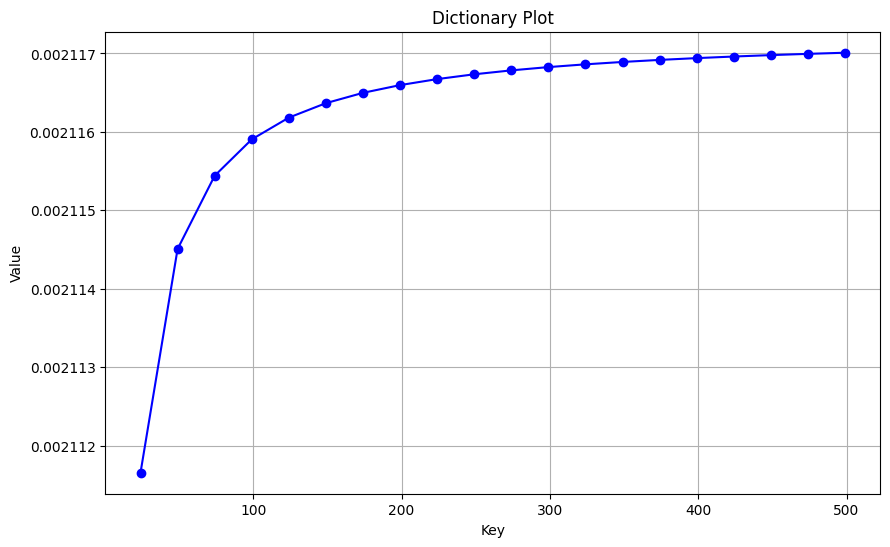

In [134]:
import matplotlib.pyplot as plt

def plot_dict(data, x_label='Key', y_label='Value', title='Dictionary Plot', till_idx=80):
    """
    Plots a dictionary with keys as x-axis and values as y-axis.

    Parameters:
    - data: dict, dictionary with keys as x values and values as y values.
    - x_label: str, label for the x-axis.
    - y_label: str, label for the y-axis.
    - title: str, title of the plot.
    """
    # Sort the dictionary by keys to ensure correct plotting order
    sorted_data = dict(sorted(data.items()))
    x = list(sorted_data.keys())[1:]
    y = list(sorted_data.values())[1:]

    # Plot the data
    plt.figure(figsize=(10, 6))
    plt.plot(x, y, marker='o', linestyle='-', color='b')
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title)
    plt.grid(True)
    plt.show()
    
plot_dict(mapes)

In [ ]:
mapes

In [87]:
print('To 2 stdevs:')

# Print results

print(f"Mean Absolute Error (MAE): {mae:.{decimals}f} ± {2 * mae_stdev:.{decimals}f}")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.{decimals}f} ± {2 * mape_stdev:.{decimals}f}")

To 2 stdevs:
Mean Absolute Error (MAE): 183.82711208 ± 983.15919964
Mean Absolute Percentage Error (MAPE): 0.00211592 ± 0.01215856


In [85]:

# mean_absolute_error_numpy(predictions, test_gibbs)

y_true = test_gibbs
y_pred = predictions
decimals = 8


y_true = (np.array(y_true)).astype(float)
y_pred = (np.array(y_pred)).astype(float)

if y_true.shape != y_pred.shape:
    raise ValueError("The lists must have the same sha2pe.")

# Mean Absolute Error
absolute_errors = np.abs(y_true - y_pred)
# print(absolute_errors)

mae = np.mean(absolute_errors)

# print(absolute_errors)

mae_stdev = np.std(absolute_errors)

# Mean Absolute Percentage Error
# Avoid division by zero
non_zero_indices = y_true != 0



abs_percentage_errors = np.abs((y_true[non_zero_indices] - y_pred[non_zero_indices]) / y_true[non_zero_indices])
mape = np.mean(abs_percentage_errors)
mape_stdev = np.std(abs_percentage_errors)

print('To 2 stdevs:')

# Print results

print(f"Mean Absolute Error (MAE): {mae:.{decimals}f} ± {2 * mae_stdev:.{decimals}f}")
print(f"Mean Absolute Percentage Error (MAPE): {mape:.{decimals}f} ± {2 * mape_stdev:.{decimals}f}")
# return mae, mae_stdev, mape, mape_stdev



To 2 stdevs:
Mean Absolute Error (MAE): 183.82711208 ± 983.15919964
Mean Absolute Percentage Error (MAPE): 0.00211592 ± 0.01215856


In [ ]:
# MAPE for original: 0.00228541 ± 0.05286643
# 

In [54]:
idx = 11

print(distances[idx])
print(closest_points[idx])
print(math.inf in gradient_array[idx])
print(gibbs_array[idx])

[0.01 0.01]
[[1.13e+03 2.00e-02 5.00e-03 1.00e-02 3.00e-02 1.95e-01 1.80e-01]
 [1.13e+03 0.00e+00 5.00e-03 1.00e-02 3.00e-02 1.95e-01 1.80e-01]]
True
[-61337.36 -60254.37]


In [56]:
for i, x in enumerate(all_gradients):
    if math.inf in x:
        print(i)
        print(x)

78
[-92.6874965283141 oo 0 0 0 0 0]
248
[-102.327782496587 oo 0 0 0 0 0]
267
[-89.4621207945948 oo 0 0 0 0 0]
338
[-93.9466465337324 oo 0 0 0 0 0]
533
[-101.172993869021 oo 0 0 0 0 0]
563
[-106.270769304340 oo 0 0 0 0 0]
726
[-95.1891421181107 oo 0 0 0 0 0]
778
[-99.7107025880934 oo 0 0 0 0 0]
779
[-103.469683738362 oo 0 0 0 0 0]
804
[-88.1389282599854 oo 0 0 0 0 0]
839
[-106.546827752393 oo 0 0 0 0 0]
907
[-97.9271343256785 oo 0 0 0 0 0]
914
[-87.4698261327581 oo 0 0 0 0 0]
1022
[-97.3253484253490 oo 0 0 0 0 0]
1102
[-104.599119667254 oo 0 0 0 0 0]
1117
[-92.0514628974593 oo 0 0 0 0 0]
1138
[-90.4418119221002 oo 0 0 0 0 0]
1225
[-98.2266447192484 oo 0 0 0 0 0]
1264
[-100.298177459688 oo 0 0 0 0 0]
1582
[-100.004871412213 oo 0 0 0 0 0]
1759
[-81.5611357151290 oo 0 0 0 0 0]
1767
[-86.4564641713335 oo 0 0 0 0 0]
1772
[-84.3932439454565 oo 0 0 0 0 0]
2049
[-96.4156271536399 oo 0 0 0 0 0]
2186
[-100.590628277674 oo 0 0 0 0 0]
2241
[-86.7955660881996 oo 0 0 0 0 0]
2290
[-96.1104732267392 oo

In [42]:
for i, x in enumerate(list(absolute_errors)):
    if x == math.inf:
        print(i)

11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
32
40
42


In [25]:
gradients={}


use_equations = non_normed_full_eq

for key in use_equations:
    gradients[key] = symbolic_gradient(use_equations[key], relevant_variables)


# Assuming `scaled_ref_data_points` is already defined
n_ref_points = len(ref_points)
n_features = len(relevant_variables)
n_gradients = len(relevant_variables)  # assuming all have the same gradient dimension

# Initialize arrays to store all gradients and gibbs energies
all_gradients = []
ref_gibbs = np.array(reference_df['Gibbs_energy'])


# Populate the arrays
for i, point in enumerate(ref_points):
    # Original point data
    original_ref_str = reference_df.iloc[i]
    
    closest_point = point
    point_dict = {relevant_variables[j]: closest_point[j] for j in range(n_features)}
    
    # Gradient expressions evaluated at the closest point
    gradient_exprs = gradients[original_ref_str.temp_class]
    # print(gradient_exprs)
    # print(point_dict)
    
    gradient_at_closest = []
    
    for grad in gradient_exprs:
        value = grad.evalf(subs=point_dict)
        gradient_at_closest.append(value)

    gradient_at_closest = np.array(gradient_at_closest)
    
    # print(gradient_at_closest)
    # exit()
    
    # gradient_at_closest = np.array([grad.evalf(subs=point_dict) for grad in gradient_exprs], dtype=np.float64)
    
    # Store in the large arrays
    all_gradients.append(gradient_at_closest)
    # all_gibbs_energies[i] = x.gibbs_energy

all_gradients = np.array(all_gradients)

In [28]:
gradients

{'nb': [-27.8784738274191*sqrt((0.00755910863898022*x0 + 1)**3)/(0.00755910863898022*x0 + 1),
  -10174.9559663857/x1**0.40618205,
  0,
  0,
  0,
  0,
  0],
 'al': [-0.018629929*x0 - 66.92056,
  3.381640982603*26288.354**(0.33228657*x1),
  0,
  0,
  0,
  0,
  0],
 'ti': [-0.029157572*x0 - 52.67735,
  16079.547*(-4 - 4/x1)/(x1 + log(x1))**5,
  0,
  0,
  0,
  0,
  0],
 'mo': [-31.7526697660184*(-sqrt(0.00355369461993378*x0 - 1) - 0.45290033711924)**2/sqrt(0.00355369461993378*x0 - 1),
  350685.689055456*x1**2,
  0,
  0,
  0,
  0,
  0],
 'fe': [x0*(0.0032811693*(x1**2)**x1 - 0.015056545) + 0.0032811693*x0*(x1**2)**x1 - 0.015056545*x0 - 57.19808,
  0.0032811693*x0**2*(log(x1**2) + 2)*(x1**2)**x1,
  0,
  0,
  0,
  0,
  0],
 'cr': [-20.030888 - 1.9960326*sqrt(x0**3)/x0,
  7657.397 + 7657.397/x1,
  0,
  0,
  0,
  0,
  0]}

In [36]:
distances, closest_points, gradient_array, gibbs_array = get_neighbors(
    query_points=query_points,
    ref_points_by_class=ref_points_by_class,
    ref_points=ref_points,  # If using absolute neighbors, pass the full set of points
    all_gradients=all_gradients,
    gradients_by_class=gradients_by_class,
    gibbs_by_class=gibbs_by_class,
    all_gibbs=ref_gibbs,
    n=NUMBER_OF_NEIGHBORS,
    relative=relative_neighbors
)

In [27]:
gradient_array[11]

array([[-86.1160269720283, -49845.2361267243, 0, 0, 0, 0, 0],
       [-86.1160269720283, oo, 0, 0, 0, 0, 0]], dtype=object)

In [15]:
query_points[11]

array([1.13e+03, 1.00e-02, 5.00e-03, 1.00e-02, 3.00e-02, 1.95e-01,
       1.80e-01])

In [16]:
closest_points[11]

array([[1.13e+03, 2.00e-02, 5.00e-03, 1.00e-02, 3.00e-02, 1.95e-01,
        1.80e-01],
       [1.13e+03, 0.00e+00, 5.00e-03, 1.00e-02, 3.00e-02, 1.95e-01,
        1.80e-01]])

In [37]:
gradient_array[11][1]

array([-86.1160269720284, oo, 0, 0, 0, 0, 0], dtype=object)

In [38]:
for i, x in enumerate(list(absolute_errors)):
    if x == math.inf:
        print(i)

11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
32
40
42


To 2 stdevs:
Mean Absolute Error (MAE): inf ± nan
Mean Absolute Percentage Error (MAPE): nan ± nan


/tmp/ipykernel_55376/3381093253.py:21: RuntimeWarning: invalid value encountered in divide
  abs_percentage_errors = np.abs((y_true[non_zero_indices] - y_pred[non_zero_indices]) / y_true[non_zero_indices])


(inf, nan, nan, nan)